# Assignment 8: SVM Classification and Random Forest Regression

In this assignment, I will build and evaluate two supervised learning models on new datasets:
- Classification: a Support Vector Machine (SVM) to predict whether a breast tumour is malignant or benign, using the Breast Cancer dataset from scikit-learn.
- Regression: a Random Forest Regressor to predict the compressive strength of concrete from its ingredients, using the Concrete Compressive Strength dataset from the UCI Machine Learning Repository.

For each task, I will load the data, split it into training and test sets, explore the training data, train the model, make predictions, and evaluate the results. I split the data before exploring it, so that no decisions are based on the test set.

# Part A: Classification - Breast Cancer Dataset

## Step 1 and 2: Load the Dataset and Split into Training and Test Sets

In [3]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, mean_squared_error, r2_score)

In [2]:
pd.set_option("display.max_columns", None)

In [4]:
# Load the Breast Cancer dataset
cancer = load_breast_cancer(as_frame=True)
cancer_df = cancer.frame
print("Shape:", cancer_df.shape)
print("Missing values:", cancer_df.isnull().sum().sum())

Shape: (569, 31)
Missing values: 0


In [6]:
print("First few rows:", cancer_df.head())

First few rows:    mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  radius error  texture error  perimeter error  \
0

In [7]:
# Show target values with their names (display only, the target itself stays 0/1)
target_names = dict(enumerate(cancer.target_names))      # {0: 'malignant', 1: 'benign'}

target_view = pd.DataFrame({
    "target": cancer_df["target"],
    "diagnosis": cancer_df["target"].map(target_names)
})
display(target_view.head(10))

# Count of each class with names
counts = cancer_df["target"].value_counts().sort_index()
counts.index = counts.index.map(lambda i: f"{i} = {target_names[i]}")
print("\nNumber of tumours in each class:")
print(counts)


,target,diagnosis
0,0,malignant
1,0,malignant
2,0,malignant
3,0,malignant
4,0,malignant
5,0,malignant
6,0,malignant
7,0,malignant
8,0,malignant
9,0,malignant



Number of tumours in each class:
target
0 = malignant    212
1 = benign       357
Name: count, dtype: int64


### Interpretation

The Breast Cancer dataset has 569 tumours, 30 features, and no missing values. The 30 features are 10 cell measurements (such as radius, texture, area, and smoothness), each summarized three ways: the mean, the standard error, and the "worst" (average of the 3 largest values).

The target is 0 = malignant (cancer) and 1 = benign (not cancer). This is the opposite of what is often expected, so I need to remember that class 0 is the cancer class when reading the results.

- Malignant: 212 tumours 
- Benign: 357 tumours

The dataset is mildly imbalanced. This is not severe enough to need techniques like SMOTE, but I used stratify when splitting to keep the same ratio in both sets, and I will focus on recall for the malignant class, because missing a cancer case is the most serious mistake.

I split the data into 80% training (455 tumours) and 20% testing (114 tumours), with random_state=42.

In [8]:
# Separate features and target, then split 80/20
X_c = cancer_df.drop("target", axis=1)
y_c = cancer_df["target"]

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_c, y_c, test_size=0.2, random_state=42, stratify=y_c
)
print("\nX_train:", X_train_c.shape, "| X_test:", X_test_c.shape)


X_train: (455, 30) | X_test: (114, 30)


## Step 3: Exploratory Data Analysis (Training Data)

In [9]:
# Summary statistics for the 10 "mean" features
mean_cols = [c for c in X_train_c.columns if c.startswith("mean")]
display(X_train_c[mean_cols].describe().round(2))

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension
count,455.00,455.00,455.00,455.00,455.00,455.00,455.00,455.00,455.00,455.00
mean,14.07,19.25,91.56,648.54,0.10,0.10,0.09,0.05,0.18,0.06
std,3.50,4.41,24.15,344.94,0.01,0.05,0.08,0.04,0.03,0.01
min,6.98,9.71,43.79,143.50,0.06,0.02,0.00,0.00,0.11,0.05
25%,11.64,16.00,74.72,415.65,0.09,0.06,0.03,0.02,0.16,0.06
50%,13.27,18.82,85.98,541.80,0.10,0.09,0.06,0.03,0.18,0.06
75%,15.74,21.71,103.70,770.05,0.10,0.13,0.13,0.07,0.20,0.07
max,28.11,39.28,188.50,2499.00,0.14,0.35,0.43,0.20,0.30,0.10


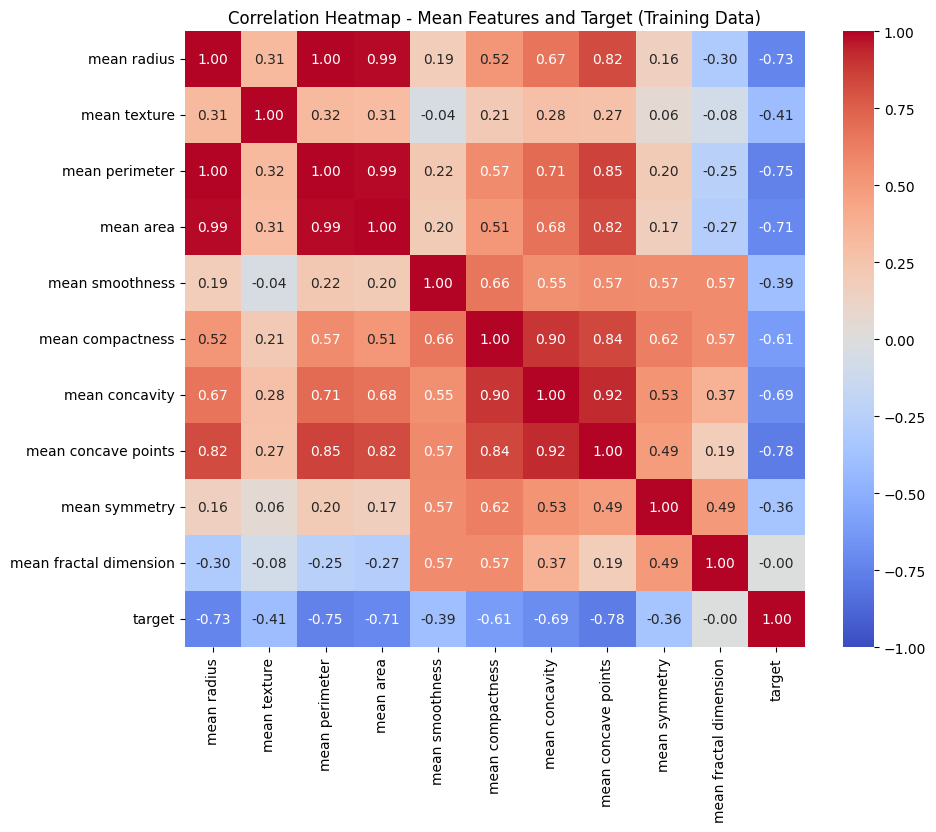

In [10]:
# Correlation heatmap of the 10 mean features + target
train_c = X_train_c[mean_cols].copy()
train_c["target"] = y_train_c
plt.figure(figsize=(10, 8))
sns.heatmap(train_c.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap - Mean Features and Target (Training Data)")
plt.show()

### Interpretation

All 10 mean features have a negative or zero correlation with the target. Since 0 = malignant and 1 = benign, a negative correlation means that higher values are linked to malignant tumours. In simple terms, larger and more irregular cells are more likely to be cancer.

- The strongest relationships with the target are mean concave points (-0.78), mean perimeter (-0.75), mean radius (-0.73), and mean area (-0.71).
- mean fractal dimension has no straight-line relationship with the target (0.00).

Multicollinearity:
- mean radius, mean perimeter, and mean area are almost perfectly correlated (0.99 to 1.00). This is expected, because perimeter and area are calculated from the radius, so they carry the same information.
- mean compactness, mean concavity, and mean concave points are also highly correlated (0.84 to 0.92), because they all describe how irregular the cell edges are.

This overlap does not hurt SVM's predictions much, but it means many features repeat the same information.

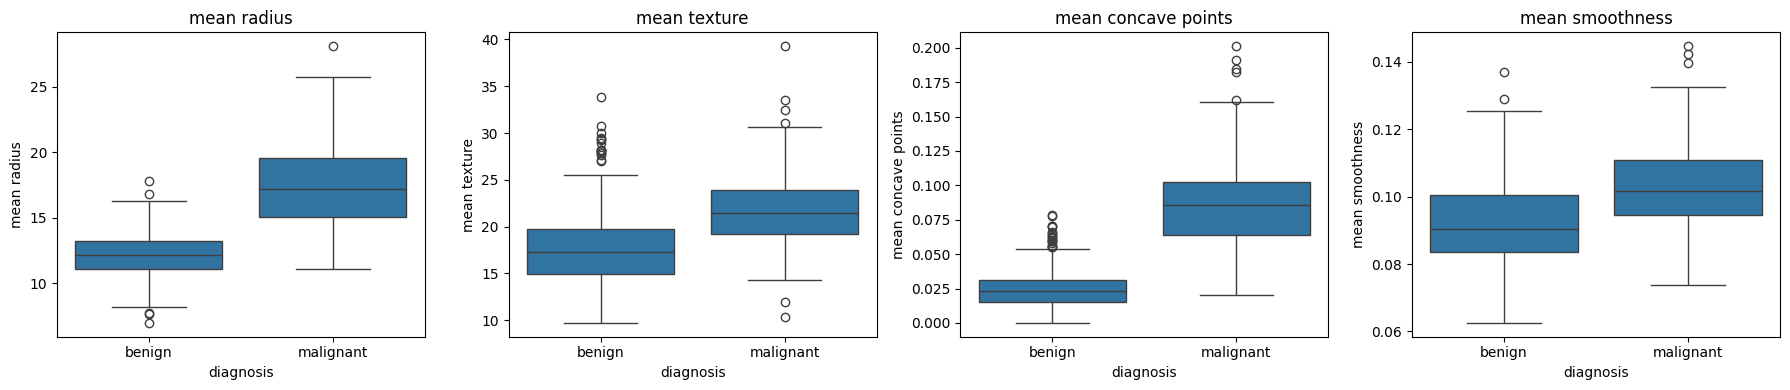

In [11]:
# Boxplots: key features by diagnosis
train_c["diagnosis"] = y_train_c.map(target_names)
key = ["mean radius", "mean texture", "mean concave points", "mean smoothness"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, key):
    sns.boxplot(data=train_c, x="diagnosis", y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### Interpretation

The boxplots compare benign and malignant tumours for four key features (training data):
- mean concave points shows the clearest difference. The boxes do not overlap: most benign tumours are below about 0.05, while most malignant tumours are above about 0.06.
- mean radius is also very different: about 12 for benign tumours and about 17 for malignant tumours, so malignant cells are larger.
- mean texture and mean smoothness are higher for malignant tumours, but the boxes overlap more, so they separate the classes less clearly. This matches their weaker correlations with the target.
- Both groups have some outliers. These are real measurements rather than errors, so I kept them.

Overall, malignant tumours have larger, rougher, and more irregular cells, and several features separate the two classes well, so a classification model should perform well.

## Step 4: Train the SVM Model and Make Predictions

In [12]:
# SVM in a Pipeline: scale the features (learned from train only), then SVC
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(random_state=42))
])
svm_model.fit(X_train_c, y_train_c)

y_pred_c = svm_model.predict(X_test_c)
print("Train accuracy:", round(accuracy_score(y_train_c, svm_model.predict(X_train_c)), 4))

Train accuracy: 0.9824


### Interpretation

I trained a Support Vector Machine (SVM) using SVC with its default settings (rbf kernel, C = 1). I placed it in a Pipeline with StandardScaler, so the features were scaled using only the training data. Scaling is important for SVM because it uses distances, and the features are on very different scales (for example, area is in the hundreds while smoothness is around 0.1).

The training accuracy is 98.24%, meaning the model classified 98% of the training tumours correctly.

## Step 5: Evaluate the Model

Test accuracy: 0.9825

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



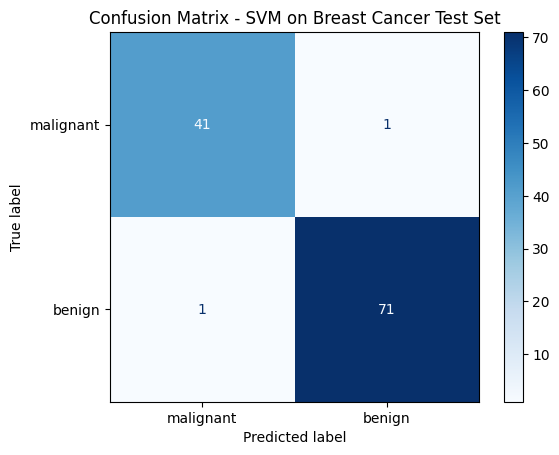

In [14]:
acc = accuracy_score(y_test_c, y_pred_c)
print("Test accuracy:", round(acc, 4))
print("\nClassification Report:")
print(classification_report(y_test_c, y_pred_c, target_names=cancer.target_names))

cm = confusion_matrix(y_test_c, y_pred_c)
ConfusionMatrixDisplay(cm, display_labels=cancer.target_names).plot(cmap="Blues")
plt.title("Confusion Matrix - SVM on Breast Cancer Test Set")
plt.show()

### Interpretation

Accuracy: the model reached 98.25% accuracy on the test set, correctly classifying 112 out of 114 tumours. The training accuracy (98.24%) is almost the same, so there is no sign of overfitting.

Confusion matrix (rows = actual, columns = predicted):
- 41 malignant tumours were correctly predicted as malignant.
- 71 benign tumours were correctly predicted as benign.
- 1 malignant tumour was wrongly predicted as benign. This is the most serious mistake, because a cancer case would be missed.
- 1 benign tumour was wrongly predicted as malignant. This is a false alarm, which would lead to extra tests but is less harmful.

Classification report:
- Malignant: precision 0.98, recall 0.98. The model caught 41 of the 42 cancer cases.
- Benign: precision 0.99, recall 0.99.
- The macro and weighted averages are both 0.98, so the model performs well on both classes despite the mild imbalance.

Overall, the SVM performed very well. In a medical setting, even one missed cancer case matters, so in practice the model could be adjusted to favour higher recall for the malignant class, for example by using class_weight="balanced" or lowering the decision threshold, even if that causes a few more false alarms.

# Part B: Regression - Concrete Compressive Strength Dataset

## Step 1 and 2: Load the Dataset and Split into Training and Test Sets

In [17]:
!pip install xlrd


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [9]:
# Load the Excel file (needs the xlrd package for .xls files)
concrete_raw = pd.read_excel("Concrete_Data.xls")
print("Original column names:")
for col in concrete_raw.columns:
    print(" -", col)

Original column names:
 - Cement (component 1)(kg in a m^3 mixture)
 - Blast Furnace Slag (component 2)(kg in a m^3 mixture)
 - Fly Ash (component 3)(kg in a m^3 mixture)
 - Water  (component 4)(kg in a m^3 mixture)
 - Superplasticizer (component 5)(kg in a m^3 mixture)
 - Coarse Aggregate  (component 6)(kg in a m^3 mixture)
 - Fine Aggregate (component 7)(kg in a m^3 mixture)
 - Age (day)
 - Concrete compressive strength(MPa, megapascals) 


In [10]:
# Shorter column names (same order as the original file)
concrete_df = concrete_raw.copy()
concrete_df.columns = ["cement", "slag", "fly_ash", "water", "superplasticizer",
                       "coarse_agg", "fine_agg", "age", "strength"]


In [11]:
print("\nShape:", concrete_df.shape)
print("Missing values:", concrete_df.isnull().sum().sum())
print("Duplicate rows:", concrete_df.duplicated().sum())
display(concrete_df.head())


Shape: (1030, 9)
Missing values: 0
Duplicate rows: 25


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [12]:
# Remove duplicate rows before splitting (prevents the same row appearing in train and test)
concrete_df = concrete_df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", concrete_df.shape)

# Separate features and target, then split 80/20
X_r = concrete_df.drop("strength", axis=1)
y_r = concrete_df["strength"]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_r, y_r, test_size=0.2, random_state=42
)
print("\nX_train:", X_train_r.shape, "| X_test:", X_test_r.shape)

Shape after removing duplicates: (1005, 9)

X_train: (804, 8) | X_test: (201, 8)


### Interpretation

The Concrete dataset has 1,030 concrete mixes and 9 columns, with no missing values. I shortened the long column names. The 8 features are the amounts of 7 ingredients (cement, blast furnace slag, fly ash, water, superplasticizer, coarse aggregate, and fine aggregate, all in kg per cubic metre) and the age of the concrete in days. The target is the compressive strength in MPa (megapascals), a continuous number, so this is a regression problem.

Zeros in slag, fly_ash, and superplasticizer are real values, meaning that ingredient was not used in the mix. They are not missing data.

I found 25 duplicate rows. I removed them before splitting, because if one copy ended up in the training set and the other in the test set, the model would be tested on data it had already seen, which would make the results look better than they really are. This left 1,005 mixes.

I split the data into 80% training (804 mixes) and 20% testing (201 mixes), with random_state=42.

## Step 3: Exploratory Data Analysis (Training Data)

In [13]:
train_r = X_train_r.copy()
train_r["strength"] = y_train_r

# Summary statistics
display(train_r.describe().round(2))

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
count,804.00,804.00,804.00,804.00,804.00,804.00,804.00,804.00,804.00
mean,278.18,72.07,56.32,182.11,6.08,972.60,773.42,45.31,35.07
std,103.94,86.09,64.35,21.54,5.95,77.29,80.92,62.35,16.02
min,102.00,0.00,0.00,121.75,0.00,801.00,594.00,1.00,3.32
25%,190.34,0.00,0.00,166.61,0.00,932.00,728.68,14.00,23.22
50%,265.50,20.00,0.00,185.70,6.12,968.00,780.20,28.00,33.74
75%,349.00,140.32,118.31,192.18,10.00,1028.40,825.00,56.00,44.39
max,540.00,359.40,200.10,246.90,32.20,1134.30,992.60,365.00,79.99


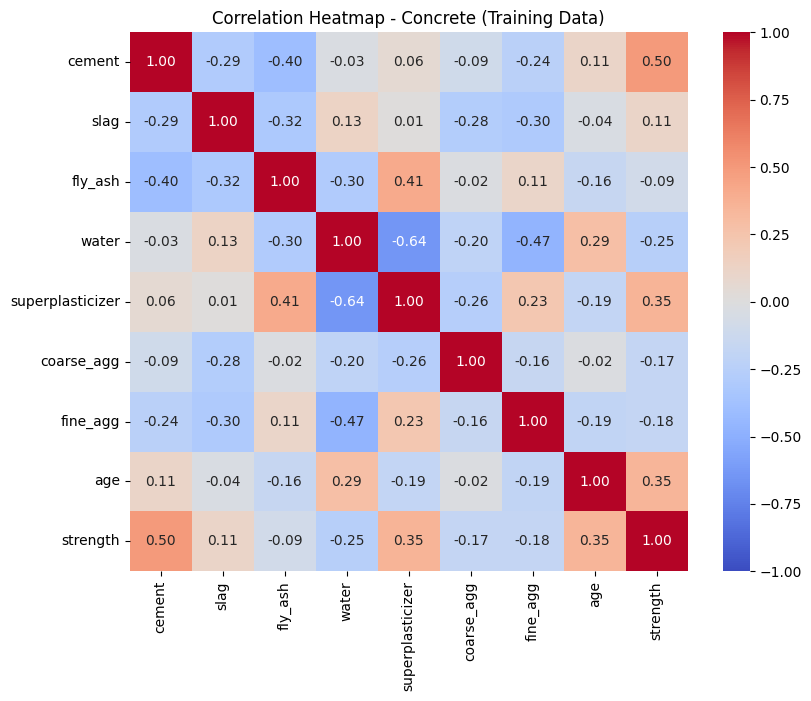

In [14]:
# Correlation heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(train_r.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap - Concrete (Training Data)")
plt.show()

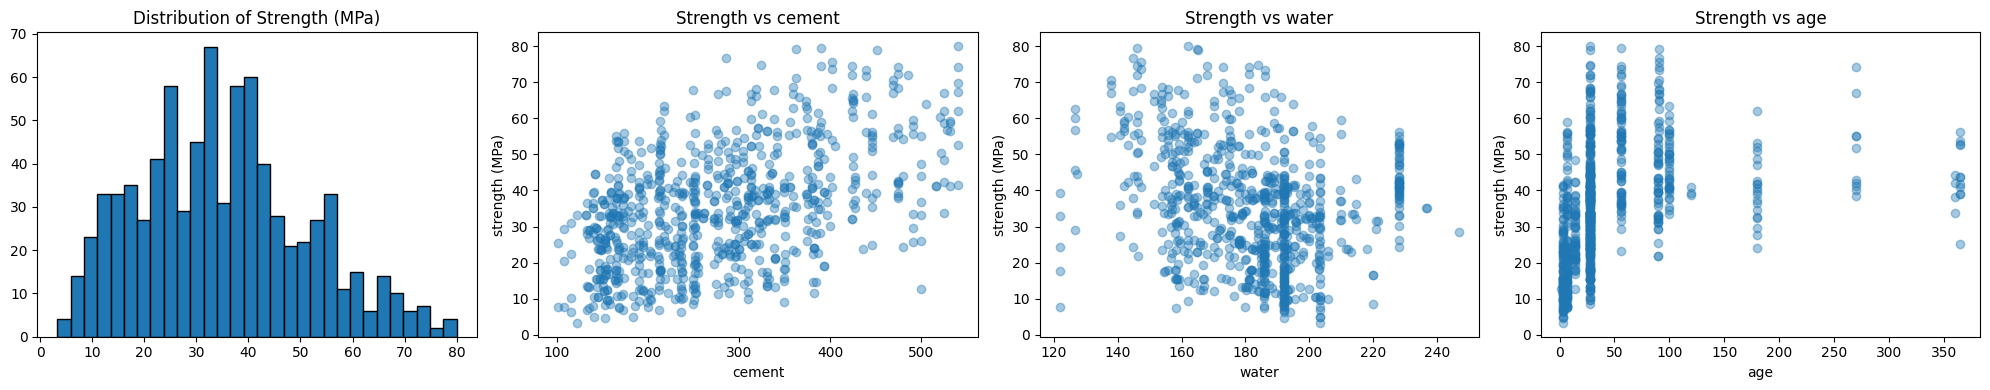

In [15]:
# Distribution of the target + strength vs key features
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].hist(train_r["strength"], bins=30, edgecolor="black")
axes[0].set_title("Distribution of Strength (MPa)")
for ax, col in zip(axes[1:], ["cement", "water", "age"]):
    ax.scatter(train_r[col], train_r["strength"], alpha=0.4)
    ax.set_xlabel(col)
    ax.set_ylabel("strength (MPa)")
    ax.set_title(f"Strength vs {col}")
plt.tight_layout()
plt.show()

### Interpretation

Distribution of strength: the target ranges from about 2 to 82 MPa and is roughly bell-shaped, centred around 35 MPa. There is no strong skew, so no transformation is needed.

Correlation with strength:
- cement has the strongest positive relationship (0.50): more cement gives stronger concrete.
- superplasticizer (0.35) and age (0.35) also have positive relationships.
- water has a negative relationship (-0.25): more water makes concrete weaker.
- The other ingredients have weak relationships with strength.

No single feature is strongly related to strength, which suggests strength depends on how ingredients combine. Also, water and superplasticizer are negatively correlated (-0.64), because superplasticizer is used to reduce the amount of water needed.

Scatter plots:
- Strength increases with cement, but the points are widely spread.
- Strength decreases slightly as water increases.
- Age only takes a few values (such as 1, 3, 7, 28, 90, and 365 days), which are standard testing days. Strength rises quickly in the first month and then levels off, so the relationship is not a straight line.

Because the relationships are non-linear and involve combinations of features, a Random Forest is a good choice. It can capture these patterns without needing feature scaling.

## Step 4: Train the Random Forest Regressor and Make Predictions

In [17]:
rf_model = RandomForestRegressor(random_state=42)
rf_model.fit(X_train_r, y_train_r)

y_pred_r = rf_model.predict(X_test_r)
y_pred_train_r = rf_model.predict(X_train_r)

### Interpretation

I trained a Random Forest Regressor with its default settings (100 decision trees) on the 804 training mixes. A Random Forest builds many decision trees, each on a random sample of the data, and averages their predictions. Averaging many trees reduces the overfitting that a single decision tree would have. I did not scale the features, because trees split on threshold values (for example, "cement > 300"), so the scale of the features does not matter.

## Step 5: Evaluate the Model

In [18]:
mse = mean_squared_error(y_test_r, y_pred_r)
print("Test MSE:", round(mse, 2))
print("Test RMSE:", round(np.sqrt(mse), 2), "MPa")
print("Test R²:", round(r2_score(y_test_r, y_pred_r), 4))
print("\nTrain RMSE:", round(np.sqrt(mean_squared_error(y_train_r, y_pred_train_r)), 2), "MPa")
print("Train R²:", round(r2_score(y_train_r, y_pred_train_r), 4))


Test MSE: 26.26
Test RMSE: 5.12 MPa
Test R²: 0.912

Train RMSE: 1.99 MPa
Train R²: 0.9845


### Interpretation
Strength is measured in MPa (megapascals), a unit of pressure. 1 MPa equals 1 newton of force per square millimetre (about 145 psi). Compressive strength shows how much pressure the concrete can take before it crushes. For example, concrete for houses is usually around 20 to 30 MPa, while high-strength concrete for bridges is 40 MPa or more.

- MSE (Mean Squared Error): 26.26. This is in MPa squared, so it is hard to interpret directly.
- RMSE (Root Mean Squared Error): 5.12 MPa. On average, the model's predictions are about 5 MPa away from the actual strength, which is roughly 14% of a typical strength of about 35 MPa.
- R²: 0.912. The model explains about 91% of the variation in concrete strength on the test set, which is a strong result.

Training vs test:
The training R² is 0.98 (RMSE 1.99 MPa), higher than the test R² of 0.91 (RMSE 5.12 MPa). This gap shows some overfitting, which is common for Random Forests because individual trees can almost memorize the training data. However, the test performance is still high, so the model generalizes well to new concrete mixes.

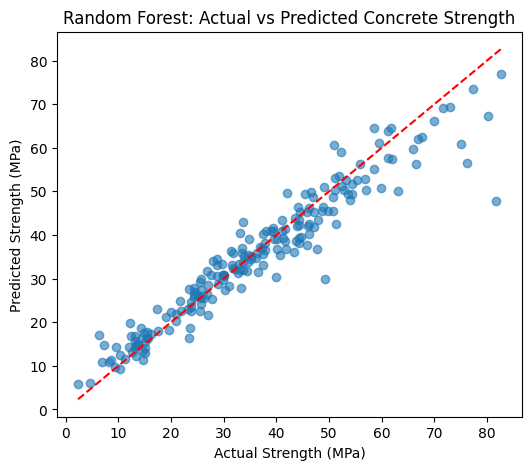

In [19]:
# Actual vs predicted
plt.figure(figsize=(6, 5))
plt.scatter(y_test_r, y_pred_r, alpha=0.6)
plt.plot([y_test_r.min(), y_test_r.max()], [y_test_r.min(), y_test_r.max()], "r--")
plt.xlabel("Actual Strength (MPa)")
plt.ylabel("Predicted Strength (MPa)")
plt.title("Random Forest: Actual vs Predicted Concrete Strength")
plt.show()

### Interpretation

Each dot is a test mix, and the red dashed line shows perfect predictions. Most dots are close to the line, especially for strengths below about 50 MPa, so the model predicts typical mixes well. For stronger concrete (above about 55 MPa), the dots spread out more and most fall below the line, meaning the model tends to underpredict very strong mixes. The largest error is a mix with an actual strength of about 82 MPa that was predicted at about 48 MPa. There are fewer very strong mixes in the data, so the model has less information to learn from in that range.

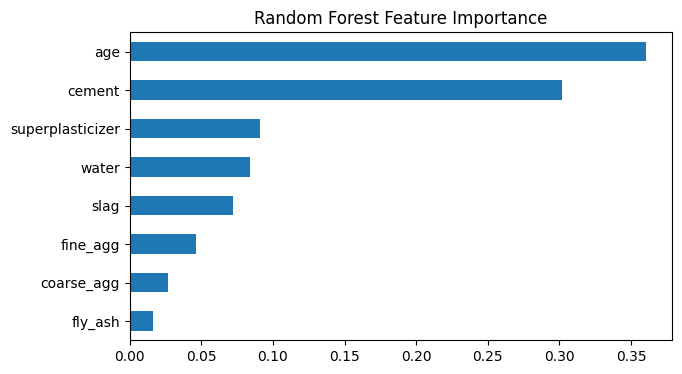

In [20]:
# Feature importance
importance = pd.Series(rf_model.feature_importances_, index=X_train_r.columns).sort_values()
importance.plot(kind="barh", figsize=(7, 4), title="Random Forest Feature Importance")
plt.show()

In [21]:
!pip install shap

  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 7.8 MB/s  0:00:00
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)

   -------------------------- ------------- 2/3 [shap]
   ---------------------------------------- 3/3 [shap]




[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


## Extra: Explaining the Model with SHAP

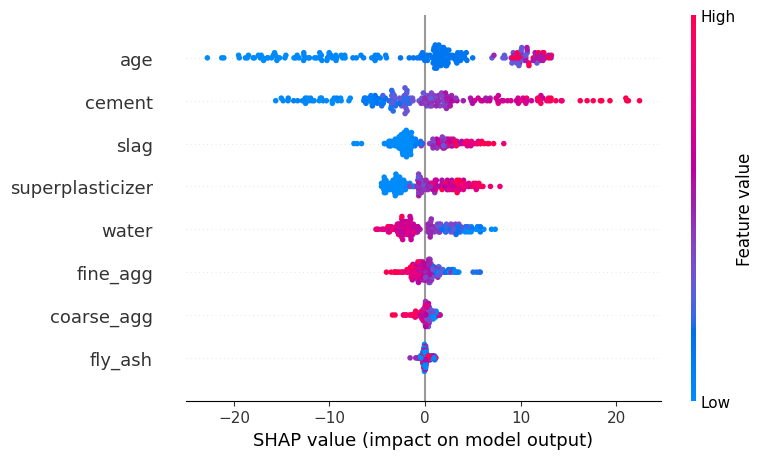

In [23]:
import shap

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test_r)

# Overall: which features matter most and in which direction
shap.summary_plot(shap_values, X_test_r)

### Interpretation: SHAP Summary Plot

- age: young concrete (blue, only a few days old) lowers the predicted strength a lot, by up to about 23 MPa. Older concrete (red and purple) raises it by about 8 to 13 MPa. So the age of the concrete has a very big effect on its strength.
- cement: mixes with little cement (blue) lower the predicted strength by up to about 16 MPa, while mixes with a lot of cement (red) raise it by up to about 22 MPa. More cement means stronger concrete, and cement has the widest range of effects of all features.
- slag and superplasticizer: higher amounts (red) increase the predicted strength and lower amounts (blue) decrease it, but the effect is smaller, mostly between -7 and +8 MPa.
- water: this works the opposite way. More water (red) lowers the predicted strength and less water (blue) raises it. This matches real life, because adding too much water makes concrete weaker.
- fine_agg: higher amounts slightly lower the strength, and lower amounts slightly raise it.
- coarse_agg and fly_ash: their effects stay very close to zero, so they hardly change the predictions.

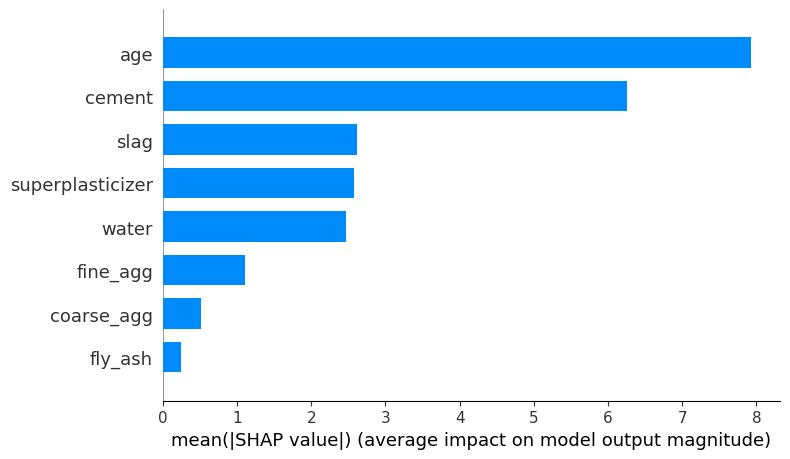

In [24]:
# Average impact (bar chart)
shap.summary_plot(shap_values, X_test_r, plot_type="bar")



### Interpretation: SHAP Bar Chart

- age has the biggest overall effect, changing the predicted strength by about 7.9 MPa on average.
- cement is second, at about 6.3 MPa.
- slag (about 2.6 MPa), superplasticizer (about 2.6 MPa), and water (about 2.5 MPa) have a medium effect.
- fine_agg (about 1.1 MPa), coarse_agg (about 0.5 MPa), and fly_ash (about 0.2 MPa) have only a small effect.

Age is the most important feature, even though its correlation with strength was only 0.35. This is because concrete gets stronger quickly in the first few weeks and then the increase slows down. This is a curved pattern, and correlation only measures straight-line relationships. The Random Forest can learn curved patterns, and SHAP shows how important age really is.

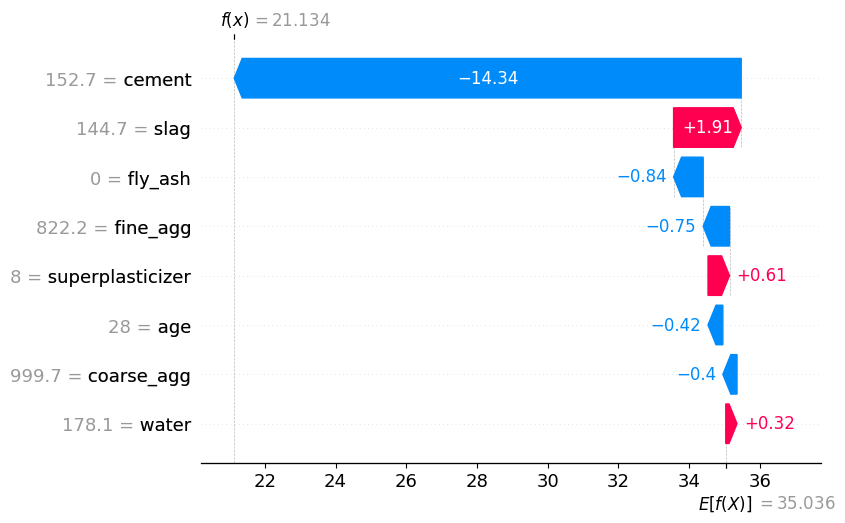

In [25]:
# One mix explained: why did the model predict this strength?
shap.plots.waterfall(explainer(X_test_r)[0])

### Interpretation: SHAP Waterfall Plot

This plot explains the prediction for the first concrete mix in the test set.

- The average predicted strength across all mixes is 35.04 MPa, but the model predicted only 21.13 MPa for this mix.
- The main reason is cement. This mix has only 152.7 kg/m³ of cement, which is low, so it lowered the prediction by 14.34 MPa.
- slag (144.7 kg/m³) increased the prediction by 1.91 MPa, superplasticizer (8 kg/m³) added 0.61 MPa, and water (178.1 kg/m³) added 0.32 MPa.
- fly_ash (0, not used) lowered the prediction by 0.84 MPa, fine_agg by 0.75 MPa, age (28 days) by 0.42 MPa, and coarse_agg by 0.40 MPa.
- In short, this mix is predicted to be weaker than average mainly because it has much less cement than a typical mix.